# Inspect recordings and mine hard-negative crops
Batch-select full `negative_mining`, hard-negative, or `normal_usage` recordings; mine where **at least one selected model** alarms at its own side thresholds; thin the union across all models to avoid nearby/overlapping crops. The same all-model union is used for the per-file count, one-recording review, and export selection—there is no separate single-model candidate path.

Inputs live in `hard_negative_mining/source_recordings/`; reviewed CSV/label pairs go to `hard_negative_mining/crops/` for manual copying into a dataset's `train_data/`. Open with the repository `.venv` kernel and run cells in order.

In [9]:
from pathlib import Path
import importlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'tap_recognition').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'tap_recognition').is_dir(), 'Open from repository root or main_notebooks/'
sys.path.insert(0, str(ROOT))
from notebooks_analysis import hard_negative_mining as mining
importlib.reload(mining)
torch.set_num_threads(2)

SOURCE_DIR = ROOT / 'temp'
INPUT_DIR = ROOT / 'hard_negative_mining/source_recordings'
OUTPUT_DIR = ROOT / 'hard_negative_mining/crops'
STAGE_NEW_RECORDINGS = False  # True to copy SOURCE_DIR; already staged inputs need no copying.

# Add/remove models here. Thresholds are manual inspection settings, not retuned exports.
MODELS = {
    'feature_0910d8(102)': {
        'checkpoint': ROOT / 'testing_checkpoints/lstm64_features/d8(102)/best.pt',
        'left_threshold': 0.9, 'right_threshold': 0.9,
    },
    'raw_0910d8(52)': {
        'checkpoint': ROOT / 'testing_checkpoints/0910d8(52)/best.pt',
        'left_threshold': 0.9, 'right_threshold': 0.9,
    },
    '1410d8(42)':{
        'checkpoint': ROOT / 'testing_checkpoints/1410d8(42)/best.pt',
        'left_threshold': 0.35, 'right_threshold': 0.35,
    }
}
RESET_AT_SEGMENTS = False  # Continuous through the whole file; always reset between files.


## 1. Stage and inventory inputs
Already staged originals in `INPUT_DIR` need no copying. Enable `STAGE_NEW_RECORDINGS` to copy raw CSVs and existing sparse `.txt` sidecars from `SOURCE_DIR`; identical copies are reused. Inventory includes source type, frames, duration and annotated events. Batch mining accepts negative-only hard-negative and normal_usage originals; a long source stays continuous during inference.

In [10]:
staged = mining.stage_recordings(SOURCE_DIR, INPUT_DIR) if STAGE_NEW_RECORDINGS else []
inventory = mining.recording_inventory(INPUT_DIR)
display(inventory)
models = {name: mining.load_mining_model(spec['checkpoint']) for name, spec in MODELS.items()}
print('Staged:', len(staged), '| models:', ', '.join(models))

,file,user,action,frames,recording_type,seconds,sample_rate_hz,sessions,annotated_events
0,imu_Miguel_negative_mining_20261009_164938.csv,Miguel,negative_mining,6002,hard_negative,60.02,100.0,1,0
1,imu_Miguel_negative_mining_20261009_165059.csv,Miguel,negative_mining,5999,hard_negative,59.99,100.0,1,0
2,imu_Miguel_negative_mining_20261009_172016.csv,Miguel,negative_mining,6003,hard_negative,60.03,100.0,1,0
3,imu_Miguel_negative_mining_20261009_172339.csv,Miguel,negative_mining,6001,hard_negative,60.01,100.0,1,0
4,imu_Miguel_negative_mining_20261009_172541.csv,Miguel,negative_mining,6001,hard_negative,60.01,100.0,1,0
5,imu_Miguel_negative_mining_20261009_172653.csv,Miguel,negative_mining,6001,hard_negative,60.01,100.0,1,0
6,imu_Miguel_negative_mining_20261009_172814.csv,Miguel,negative_mining,5998,hard_negative,59.98,100.0,1,0
7,imu_Miguel_negative_mining_20261009_172921.csv,Miguel,negative_mining,5999,hard_negative,59.99,100.0,1,0
8,imu_Miguel_negative_mining_20261009_173235.csv,Miguel,negative_mining,5999,hard_negative,59.99,100.0,1,0
9,imu_Miguel_negative_mining_20261009_173341.csv,Miguel,negative_mining,5999,hard_negative,59.99,100.0,1,0


Staged: 0 | models: feature_0910d8(102), raw_0910d8(52), 1410d8(42)


## 2. Batch mining: select originals and mine the union of model failures
Set `BATCH_FILES` to inventory basenames, or enable `BATCH_SELECT_ALL` for all negative-only hard-negative/normal-use originals. Every model keeps its own thresholds from `MODELS`. `BATCH_MIN_GAP_FRAMES=300` skips the next 300 anchor frames after each kept failure; by default crops also cannot overlap, including boundary-slid duplicates. Source copies are deduplicated by hash. Statistics include zero-crop recordings. Short sessions that cannot fit a full crop and candidates whose core would be truncated by training are skipped. Nothing is saved until `SAVE_BATCH_CROPS=True`.


In [11]:
BATCH_FILES = ['imu_Miguel_negative_mining_20261009_164938.csv', ]  # e.g. ['imu_Miguel_normal_usage_20261014_120000.csv']
BATCH_SELECT_ALL = True
BATCH_MODELS = list(MODELS)
BATCH_MIN_GAP_FRAMES = 50
BATCH_ALLOW_OVERLAPPING_CROPS = True
BATCH_CROP_SECONDS = 3.0
BATCH_CONTEXT_BEFORE_SECONDS = 2.5
BATCH_LOOKAHEAD_FRAMES = 0
BATCH_REFRACTORY_FRAMES = 50
BATCH_TRAINING_WINDOW_FRAMES = 300
SAVE_ALL_BATCH_CROPS = False  # True writes every all-model union candidate from this batch.
assert BATCH_MODELS and set(BATCH_MODELS) <= set(MODELS)
batch_thresholds = {name: (MODELS[name]['left_threshold'], MODELS[name]['right_threshold']) for name in BATCH_MODELS}
eligible = inventory[(inventory.recording_type.isin(['hard_negative', 'normal_usage'])) &
                     (inventory.annotated_events == 0) & ~inventory.file.str.contains('__crop_', regex=False)]
batch_files = eligible.file.tolist() if BATCH_SELECT_ALL else list(BATCH_FILES)
assert len(batch_files) == len(set(batch_files)) and set(batch_files) <= set(eligible.file), 'Choose eligible original basenames'
batch_candidates, batch_file_stats, batch_stats = mining.mine_recordings(
    [INPUT_DIR / file for file in batch_files], {name: models[name] for name in BATCH_MODELS},
    batch_thresholds, min_gap_frames=BATCH_MIN_GAP_FRAMES,
    allow_overlapping_crops=BATCH_ALLOW_OVERLAPPING_CROPS, crop_seconds=BATCH_CROP_SECONDS,
    context_before_seconds=BATCH_CONTEXT_BEFORE_SECONDS, lookahead_frames=BATCH_LOOKAHEAD_FRAMES,
    refractory_frames=BATCH_REFRACTORY_FRAMES, anchor='peak', before_frames=40, after_frames=10,
    training_window_frames=BATCH_TRAINING_WINDOW_FRAMES, reset_at_segments=RESET_AT_SEGMENTS)
display(pd.DataFrame([batch_stats]))
display(batch_file_stats)
display(batch_candidates)
batch_exports = (mining.export_batch(batch_candidates, models, INPUT_DIR, OUTPUT_DIR,
                                    BATCH_TRAINING_WINDOW_FRAMES) if SAVE_ALL_BATCH_CROPS else pd.DataFrame())
if SAVE_ALL_BATCH_CROPS:
    print(f'Exported/reused every batch candidate: {len(batch_exports)} crop(s).')
    display(batch_exports)
if not batch_files: print('Select BATCH_FILES or enable BATCH_SELECT_ALL, then rerun this cell.')


,recordings,crops,recording_minutes,recording_seconds,crop_seconds,crop_minutes,crops_per_minute
0,51,87,150.84,9050.4,261.0,4.35,0.57677


,file,source_sha256,recording_seconds,recording_minutes,crops,crops_per_minute,crop_seconds,crop_minutes
0,imu_Miguel_negative_mining_20261009_164938.csv,ed7ea66b25a72b7aeaf779943fc6ced6526fda28683ec1...,60.02,1.000333,0,0.000000,0.0,0.00
1,imu_Miguel_negative_mining_20261009_165059.csv,7158f146e37004945919ce69de90422f2ce74c0b3bf29a...,59.99,0.999833,2,2.000333,6.0,0.10
2,imu_Miguel_negative_mining_20261009_172016.csv,b594aaa0d5eec37157c1614a02271da4853b90a5d0a2d4...,60.03,1.000500,0,0.000000,0.0,0.00
3,imu_Miguel_negative_mining_20261009_172339.csv,8be79bfb9ce882400eec0e8dacb7e7cce31514a5d067c5...,60.01,1.000167,1,0.999833,3.0,0.05
4,imu_Miguel_negative_mining_20261009_172541.csv,344a97f42496340dcd1c08f3d624950e3e3330798921cc...,60.01,1.000167,1,0.999833,3.0,0.05
5,imu_Miguel_negative_mining_20261009_172653.csv,be1141295b596f79df09dcd71707b3037b1e73c9bcb94b...,60.01,1.000167,0,0.000000,0.0,0.00
6,imu_Miguel_negative_mining_20261009_172814.csv,3ea8ed2a4e1700f6f528fc6da4457dde4cdb3d09055039...,59.98,0.999667,8,8.002668,24.0,0.40
7,imu_Miguel_negative_mining_20261009_172921.csv,c7299ad11857d3ed418af6e1a4a70519806be8a9def103...,59.99,0.999833,0,0.000000,0.0,0.00
8,imu_Miguel_negative_mining_20261009_173235.csv,8f6e89fbce40c2be84b2eb4ed9af0c911d3c8fc95531c2...,59.99,0.999833,0,0.000000,0.0,0.00
9,imu_Miguel_negative_mining_20261009_173341.csv,933cb5a2267265efc679626a106277dea4cb3fa3288b3d...,59.99,0.999833,1,1.000167,3.0,0.05


,candidate_id,file,source_sha256,model,class_id,side,probability,left_threshold,right_threshold,lookahead_frames,...,core_end_frame,context_clipped,training_retains_core,annotated_events_in_crop,trigger_models,trigger_details,selection_mode,min_gap_frames,allow_overlapping_crops,mining_models
0,0,imu_Miguel_negative_mining_20261009_165059.csv,7158f146e37004945919ce69de90422f2ce74c0b3bf29a...,1410d8(42),1,left,0.408238,0.35,0.35,0,...,2196,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 1, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
1,1,imu_Miguel_negative_mining_20261009_165059.csv,7158f146e37004945919ce69de90422f2ce74c0b3bf29a...,1410d8(42),2,right,0.350024,0.35,0.35,0,...,3171,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 2, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
2,2,imu_Miguel_negative_mining_20261009_172339.csv,8be79bfb9ce882400eec0e8dacb7e7cce31514a5d067c5...,1410d8(42),2,right,0.401483,0.35,0.35,0,...,2281,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 2, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
3,3,imu_Miguel_negative_mining_20261009_172541.csv,344a97f42496340dcd1c08f3d624950e3e3330798921cc...,1410d8(42),1,left,0.482194,0.35,0.35,0,...,1078,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 1, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
4,4,imu_Miguel_negative_mining_20261009_172814.csv,3ea8ed2a4e1700f6f528fc6da4457dde4cdb3d09055039...,feature_0910d8(102),1,left,0.939639,0.9,0.9,0,...,297,False,True,0,[feature_0910d8(102)],"[{'model': 'feature_0910d8(102)', 'class_id': ...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,82,imu_Miguel_normal_usage_20261014_092309.csv,1098fd90ec8a836f7eb399c4a7e872913e2201629c3d6d...,1410d8(42),1,left,0.484933,0.35,0.35,0,...,5973,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 1, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
83,83,imu_Miguel_normal_usage_20261014_092817.csv,f5a191d54d33a8494c64445a5cd434a7240a539f1496fe...,1410d8(42),2,right,0.402051,0.35,0.35,0,...,18776,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 2, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
84,84,imu_Miguel_normal_usage_20261014_092932.csv,94e47482b228ed56c738b5729140a8f49c50257f72fefe...,1410d8(42),1,left,0.365457,0.35,0.35,0,...,4214,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 1, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."
85,85,imu_Miguel_normal_usage_20261014_105413.csv,0138f2d69a3462b83c24a683a15dd210780f1bd0def570...,1410d8(42),2,right,0.438929,0.35,0.35,0,...,949,False,True,0,[1410d8(42)],"[{'model': '1410d8(42)', 'class_id': 2, 'proba...",any_model,50,True,"[{'model': 'feature_0910d8(102)', 'checkpoint_..."


In [12]:
batch_candidates['model'].value_counts()

model
1410d8(42)             76
feature_0910d8(102)    10
raw_0910d8(52)          1
Name: count, dtype: int64

## 3. Review and export one source file using the all-model union
Choose a file from the batch selection below. Its count and table are the exact union that produced `batch_file_stats`: all `BATCH_MODELS` apply their own side thresholds, then the shared gap/overlap rules are applied once. This prevents the old single-model review from showing fewer crops than the per-file batch count.

The whole-recording and crop zoom plots overlay every batch model. `model` is the representative trigger that first kept the candidate; `trigger_models` records every model whose alarm contributed to it. Set `REVIEW_KEEP_IDS` only after reviewing, then enable `SAVE_REVIEWED_CROPS` to write those candidates. To write **every** candidate without review, set `SAVE_ALL_BATCH_CROPS=True` in the batch-mining settings and rerun that cell. Nothing is exported by default.


,file,source_sha256,recording_seconds,recording_minutes,crops,crops_per_minute,crop_seconds,crop_minutes
29,imu_Miguel_normal_usage_20261013_181906.csv,25a843e4683f3254c787d6d3a7a5162e03b2110d568fd0...,300.0,5.0,6,1.2,18.0,0.3


,candidate_id,model,trigger_models,side,probability,anchor_frame,anchor_seconds,crossing_frame,peak_frame,alarm_frame,crop_start_frame,crop_end_frame,crop_seconds,training_retains_core
56,56,1410d8(42),[1410d8(42)],right,0.532693,2294,22.94,2294,2294,2294,2044,2344,3.0,True
57,57,1410d8(42),[1410d8(42)],right,0.436441,5448,54.48,5448,5448,5448,5198,5498,3.0,True
58,58,1410d8(42),[1410d8(42)],right,0.364213,8834,88.34,8834,8834,8834,8584,8884,3.0,True
59,59,1410d8(42),[1410d8(42)],right,0.445883,9328,93.28,9328,9328,9328,9078,9378,3.0,True
60,60,1410d8(42),[1410d8(42)],left,0.383931,13145,131.45,13145,13145,13145,12895,13195,3.0,True
61,61,1410d8(42),[1410d8(42)],left,0.40887,19789,197.89,19789,19789,19789,19539,19839,3.0,True


imu_Miguel_normal_usage_20261013_181906.csv: 6 all-model union candidates; 0 selected for export.


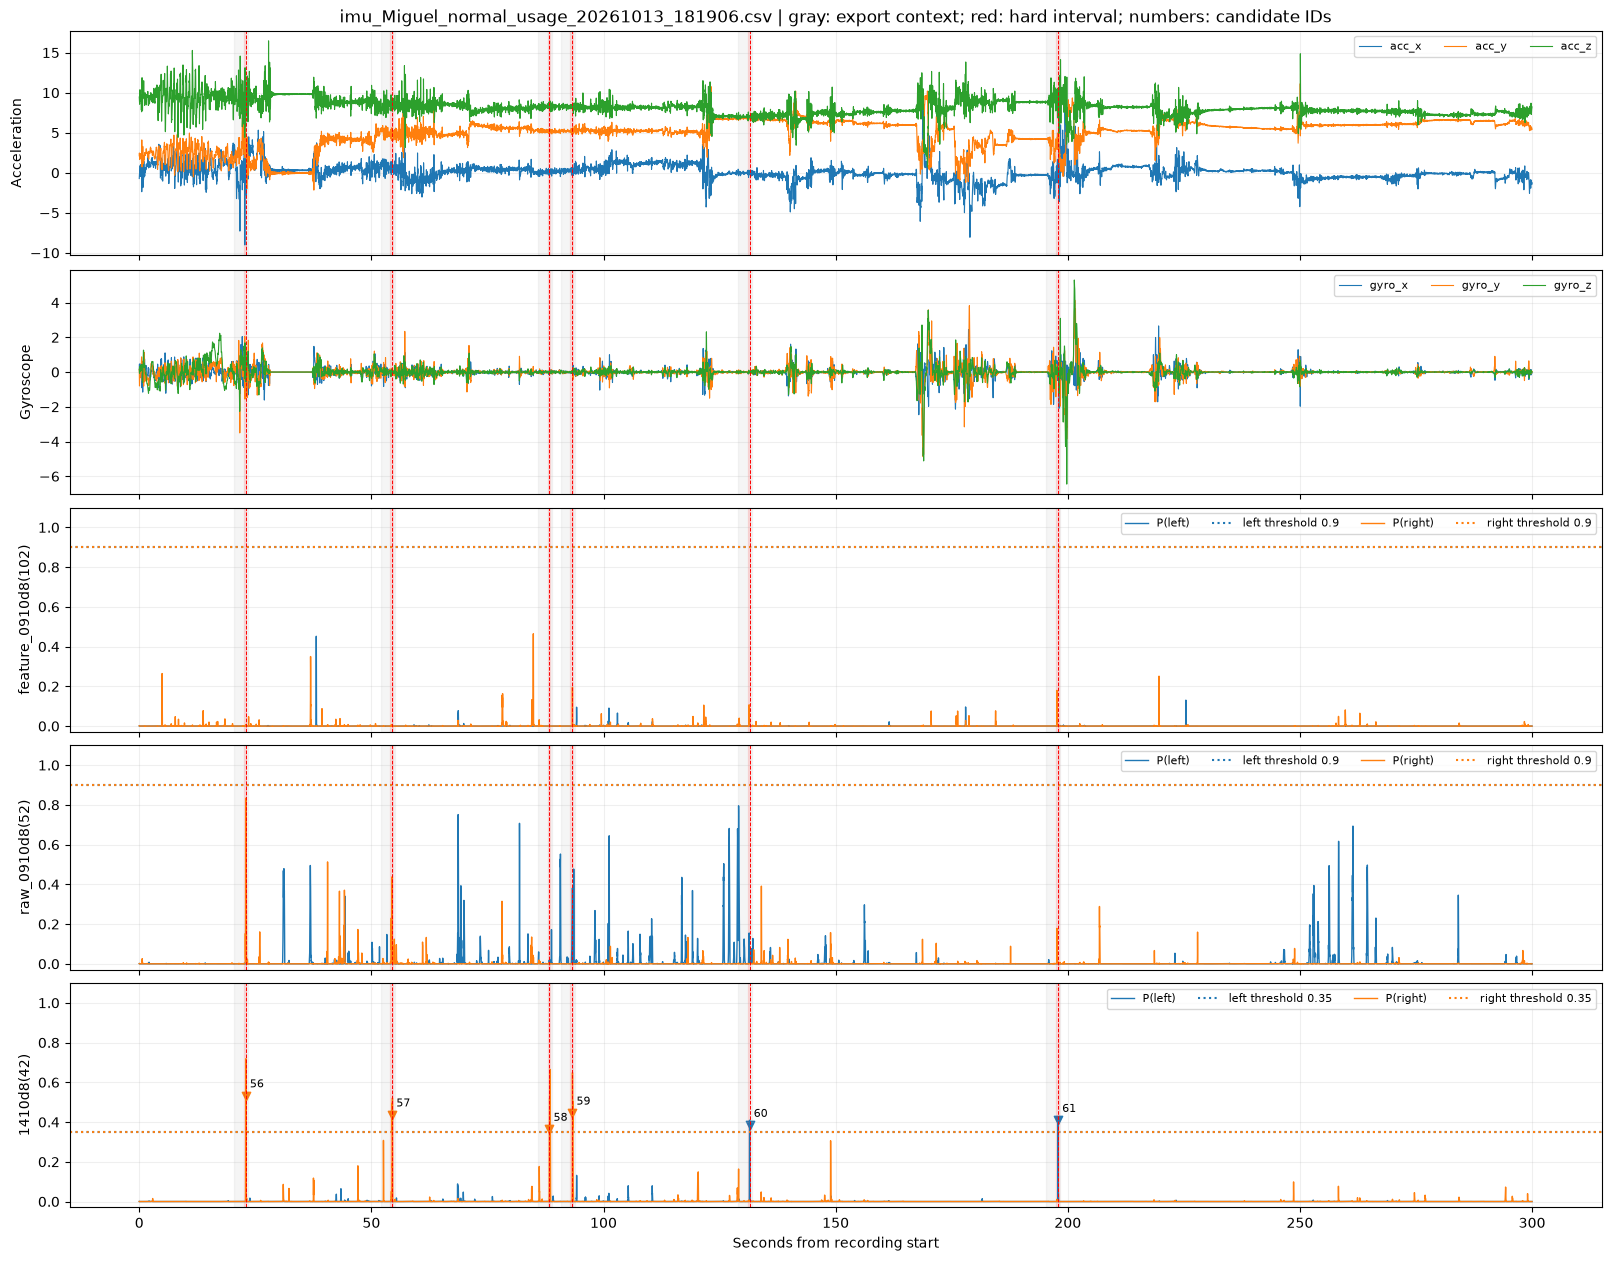

""


Crops currently in /home/aprohack/desktop/work/tap-project/project/tapRecognitionRui/TapRecognition/hard_negative_mining/crops


""


In [15]:
# This file must be included by BATCH_FILES/BATCH_SELECT_ALL above.
REVIEW_FILE = 	'imu_Miguel_normal_usage_20261013_181906.csv'
REVIEW_CANDIDATE_ID = None  # Global candidate ID; None displays the full all-model union.
REVIEW_KEEP_IDS = []  # Global candidate IDs to export; [] prevents accidental saving.
SAVE_REVIEWED_CROPS = False
FULL_INFERENCE_CHUNK_FRAMES = 4096

assert REVIEW_FILE in set(batch_files), 'Choose a file included in the batch selection, then rerun the batch-mining cell.'
review_candidates = batch_candidates[batch_candidates.file == REVIEW_FILE].copy()
review_stats = batch_file_stats[batch_file_stats.file == REVIEW_FILE]
assert len(review_stats) == 1
assert len(REVIEW_KEEP_IDS) == len(set(REVIEW_KEEP_IDS))
assert set(REVIEW_KEEP_IDS) <= set(review_candidates.candidate_id), 'Unknown candidate ID; rerun batch mining.'
if REVIEW_CANDIDATE_ID is not None:
    assert REVIEW_CANDIDATE_ID in set(review_candidates.candidate_id), 'Unknown candidate ID; rerun batch mining.'

REVIEW_COLUMNS = ['candidate_id', 'model', 'trigger_models', 'side', 'probability',
                  'anchor_frame', 'anchor_seconds', 'crossing_frame', 'peak_frame',
                  'alarm_frame', 'crop_start_frame', 'crop_end_frame', 'crop_seconds',
                  'training_retains_core']
display(review_stats)
display(review_candidates[REVIEW_COLUMNS])
print(f'{REVIEW_FILE}: {len(review_candidates)} all-model union candidates; '
      f'{len(REVIEW_KEEP_IDS)} selected for export.')

recording = mining.load_recording(INPUT_DIR / REVIEW_FILE)
review_traces = {name: mining.predict_recording(recording, models[name], RESET_AT_SEGMENTS,
                                                 FULL_INFERENCE_CHUNK_FRAMES)
                 for name in BATCH_MODELS}
mining.plot_recording(recording, review_traces, batch_thresholds, review_candidates)
plt.show()

if REVIEW_CANDIDATE_ID is not None:
    preview = review_candidates[review_candidates.candidate_id == REVIEW_CANDIDATE_ID]
    row = preview.iloc[0]
    display(preview[REVIEW_COLUMNS])
    mining.plot_recording(recording, review_traces, batch_thresholds, preview,
                          int(row.crop_start_frame), int(row.crop_end_frame))
    plt.show()

reviewed = review_candidates[review_candidates.candidate_id.isin(REVIEW_KEEP_IDS)].copy()
exports = (mining.export_batch(reviewed, models, INPUT_DIR, OUTPUT_DIR,
                                BATCH_TRAINING_WINDOW_FRAMES)
           if SAVE_REVIEWED_CROPS else pd.DataFrame())
display(exports)
print('Crops currently in', OUTPUT_DIR)
display(mining.recording_inventory(OUTPUT_DIR))
